<a href="https://colab.research.google.com/github/INYOUNG98/news-sentiment-stock/blob/main/01_%EC%A3%BC%EA%B0%80%EB%8D%B0%EC%9D%B4%ED%84%B0ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

              Open    High     Low   Close    Volume    Change
Date                                                          
2026-01-02  120200  128500  120200  128500  30463279  0.071726
2026-01-05  134600  138600  133600  138100  42863376  0.074708
2026-01-06  135300  139300  132700  138900  45321341  0.005793
2026-01-07  143500  144400  137600  141000  46317413  0.015119
2026-01-08  138300  144500  138300  138800  41449329 -0.015603
0 건 수집


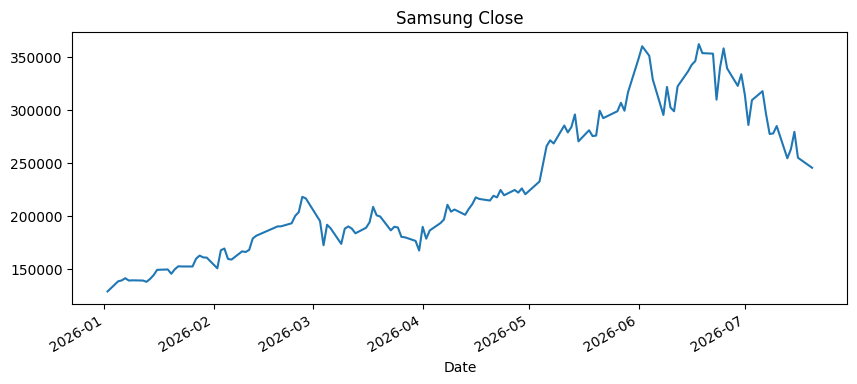

In [ ]:
!pip install finance-datareader

import FinanceDataReader as fdr

# 삼성전자(005930) 2026년 1월부터 주가
df = fdr.DataReader('005930', '2026-01-01')

# 앞 5행 확인
print(df.head())

# 종가 그래프
df['Close'].plot(figsize=(10,4), title='Samsung Close')

# 기초통계량
df.describe()

import requests
from bs4 import BeautifulSoup

url = 'https://finance.naver.com/item/news_news.naver?code=005930&page=1'
headers = {'User-Agent': 'Mozilla/5.0'}
res = requests.get(url, headers=headers)
soup = BeautifulSoup(res.text, 'html.parser')

titles = soup.select('td.title a')
for t in titles[:10]:
    print(t.text.strip())

import requests
import pandas as pd
from bs4 import BeautifulSoup
import time

news_list = []
headers = {'User-Agent': 'Mozilla/5.0'}

for page in range(1, 31):
    url = f'https://finance.naver.com/item/news_news.naver?code=005930&page={page}'
    res = requests.get(url, headers=headers)
    soup = BeautifulSoup(res.text, 'html.parser')

    titles = soup.select('td.title a')
    dates = soup.select('td.date')

    for t, d in zip(titles, dates):
        news_list.append({
            'date': d.text.strip(),
            'title': t.text.strip()
        })
    time.sleep(0.5)

news_df = pd.DataFrame(news_list)
print(len(news_df), '건 수집')
news_df.head(10)



news_df.to_csv('samsung_news.csv', index=False)


In [ ]:
import requests
from bs4 import BeautifulSoup

url = 'https://finance.naver.com/item/news_news.naver?code=005930&page=1'
headers = {'User-Agent': 'Mozilla/5.0'}
res = requests.get(url, headers=headers)
soup = BeautifulSoup(res.text, 'html.parser')

print('상태코드:', res.status_code)
print('제목 개수:', len(soup.select('td.title a')))
print('날짜 개수:', len(soup.select('td.date')))


상태코드: 200
제목 개수: 0
날짜 개수: 0


In [ ]:
print(len(res.text))
print(res.text[:600])


6216
<html lang="ko">
<head>
<meta http-equiv="Content-Type" content="text/html; charset=euc-kr">
<title>Npay 증권</title>

<link rel="stylesheet" type="text/css" href="https://ssl.pstatic.net/imgstock/static.pc/20260709231055/css/newstock.css">
<link rel="stylesheet" type="text/css" href="https://ssl.pstatic.net/imgstock/static.pc/20260709231055/css/common.css">
<link rel="stylesheet" type="text/css" href="https://ssl.pstatic.net/imgstock/static.pc/20260709231055/css/layout.css">
<link rel="stylesheet" type="text/css" href="https://ssl.pstatic.net/imgstock/static.pc/20260709231055/css/main.css">
<li


In [ ]:
import requests
import pandas as pd
import time

news_list = []
headers = {'User-Agent': 'Mozilla/5.0'}

for page in range(1, 31):
    url = f'https://m.stock.naver.com/api/news/stock/005930?pageSize=20&page={page}'
    res = requests.get(url, headers=headers)
    data = res.json()

    for group in data:
        for item in group.get('items', []):
            news_list.append({
                'date': item.get('datetime'),
                'title': item.get('title')
            })
    time.sleep(0.3)

news_df = pd.DataFrame(news_list)
print(len(news_df), '건 수집')
news_df.head(10)


600 건 수집


,date,title
0,202607201205,"수익 상위 1%, 삼전 사고 닉스 팔았다…급락장서 엇갈린 베팅[주식 초..."
1,202607201204,"&quot;유럽 항공우주 심장부로 간다&quot;…과기부, 佛 툴루즈서 AI·반도체..."
2,202607201201,최태원 &quot;메모리 달라고 아비규환&quot; / 구자철 &quot;한국 축구...
3,202607201200,"과기정통부, 글로벌 인재유치 유럽으로 확대…온라인 플랫폼도 첫 선"
4,202607201200,‘블랙 먼데이’ 코스피·코스닥 매도사이드카
5,202607201200,"없어서 못 파는 메모리, 벌써 공급 과잉 우려?…&quot;상승 사이클 끝&quot..."
6,202607201200,'5조 통 큰 약속' 첫걸음…'이 회사' 한 달만 1조 풀었다
7,202607201159,"&quot;달려도 모자랄 판에&quot; 현대차 노조, 日 8시간 파업..생산 차질 확대"
8,202607201156,코스피 장중 6500선 붕괴…코스닥은 52주 신저가 기록[장중시황]
9,202607201155,코스닥 이어 코스피도 멈췄다…올해 20번째 '매도 사이드카'


In [ ]:
# 날짜를 보기 좋은 형태로 변환 (202607201030 → 2026-07-20)
news_df['date'] = pd.to_datetime(news_df['date'], format='%Y%m%d%H%M')
news_df['day'] = news_df['date'].dt.date

# 중복 제목 제거
news_df = news_df.drop_duplicates(subset='title')

print(len(news_df), '건 (중복 제거 후)')
print(news_df['day'].min(), '~', news_df['day'].max())
news_df.head()


447 건 (중복 제거 후)
2026-07-19 ~ 2026-07-20


,date,title,day
0,2026-07-20 12:05:00,"수익 상위 1%, 삼전 사고 닉스 팔았다…급락장서 엇갈린 베팅[주식 초...",2026-07-20
1,2026-07-20 12:04:00,"&quot;유럽 항공우주 심장부로 간다&quot;…과기부, 佛 툴루즈서 AI·반도체...",2026-07-20
2,2026-07-20 12:01:00,최태원 &quot;메모리 달라고 아비규환&quot; / 구자철 &quot;한국 축구...,2026-07-20
3,2026-07-20 12:00:00,"과기정통부, 글로벌 인재유치 유럽으로 확대…온라인 플랫폼도 첫 선",2026-07-20
4,2026-07-20 12:00:00,‘블랙 먼데이’ 코스피·코스닥 매도사이드카,2026-07-20


In [ ]:
news_df.to_csv('samsung_news.csv', index=False)


In [ ]:
!pip install konlpy
!wget -q https://raw.githubusercontent.com/park1200656/KnuSentiLex/master/SentiWord_Dict.txt


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.5/438.5 kB 16.1 MB/s eta 0:00:00


In [ ]:
senti_dict = {}
with open('SentiWord_Dict.txt', encoding='utf-8') as f:
    for line in f:
        parts = line.strip().split('\t')
        if len(parts) == 2:
            word, score = parts
            senti_dict[word] = int(score)

print(len(senti_dict), '개 단어 로드')
print(senti_dict.get('상승'), senti_dict.get('하락'))


14851 개 단어 로드
None None


In [ ]:
from konlpy.tag import Okt
okt = Okt()

def senti_score(title):
    words = okt.morphs(str(title))   # 제목을 단어 단위로 쪼개기
    return sum(senti_dict.get(w, 0) for w in words)

news_df['senti'] = news_df['title'].apply(senti_score)
news_df[['title', 'senti']].head(15)


,title,senti
0,"수익 상위 1%, 삼전 사고 닉스 팔았다…급락장서 엇갈린 베팅[주식 초...",3
1,"&quot;유럽 항공우주 심장부로 간다&quot;…과기부, 佛 툴루즈서 AI·반도체...",1
2,최태원 &quot;메모리 달라고 아비규환&quot; / 구자철 &quot;한국 축구...,4
3,"과기정통부, 글로벌 인재유치 유럽으로 확대…온라인 플랫폼도 첫 선",0
4,‘블랙 먼데이’ 코스피·코스닥 매도사이드카,0
5,"없어서 못 파는 메모리, 벌써 공급 과잉 우려?…&quot;상승 사이클 끝&quot...",1
6,'5조 통 큰 약속' 첫걸음…'이 회사' 한 달만 1조 풀었다,0
7,"&quot;달려도 모자랄 판에&quot; 현대차 노조, 日 8시간 파업..생산 차질 확대",2
8,코스피 장중 6500선 붕괴…코스닥은 52주 신저가 기록[장중시황],0
9,코스닥 이어 코스피도 멈췄다…올해 20번째 '매도 사이드카',0


In [ ]:
# 날짜별 평균 감성 점수
daily_senti = news_df.groupby('day')['senti'].mean().reset_index()
daily_senti.columns = ['day', 'avg_senti']
print(daily_senti)


          day  avg_senti
0  2026-07-19   0.282051
1  2026-07-20   0.182540


In [ ]:
import FinanceDataReader as fdr

price = fdr.DataReader('005930', '2026-06-01')
price = price.reset_index()
price['day'] = price['Date'].dt.date

merged = pd.merge(price, daily_senti, on='day', how='inner')
print(len(merged), '일치하는 날짜')
merged[['day', 'Close', 'avg_senti']]


1 일치하는 날짜


,day,Close,avg_senti
0,2026-07-20,245000,0.18254


In [ ]:
import requests
import pandas as pd
import time

news_list = []
headers = {'User-Agent': 'Mozilla/5.0'}

for page in range(1, 501):   # 500페이지 = 약 1만 건
    url = f'https://m.stock.naver.com/api/news/stock/005930?pageSize=20&page={page}'
    res = requests.get(url, headers=headers)
    data = res.json()

    if not data:          # 더 이상 뉴스가 없으면 중단
        print(page, '페이지에서 종료')
        break

    for group in data:
        for item in group.get('items', []):
            news_list.append({
                'date': item.get('datetime'),
                'title': item.get('title')
            })

    if page % 50 == 0:    # 50페이지마다 진행 상황 출력
        print(page, '페이지 완료,', len(news_list), '건')
    time.sleep(0.3)

news_df = pd.DataFrame(news_list)
print('총', len(news_df), '건 수집')


50 페이지 완료, 1000 건
100 페이지 완료, 2000 건
101 페이지에서 종료
총 2000 건 수집


In [ ]:
news_df['date'] = pd.to_datetime(news_df['date'], format='%Y%m%d%H%M')
news_df['day'] = news_df['date'].dt.date
news_df = news_df.drop_duplicates(subset='title')

print(len(news_df), '건 (중복 제거 후)')
print(news_df['day'].min(), '~', news_df['day'].max())


1635 건 (중복 제거 후)
2026-07-15 ~ 2026-07-20


In [ ]:
import requests

headers = {'User-Agent': 'Mozilla/5.0'}

# 후보 종목들
candidates = {
    '한샘': '009240',
    '풀무원': '017810',
    '더존비즈온': '012510',
    'DL이앤씨': '375500',
}

for name, code in candidates.items():
    url = f'https://m.stock.naver.com/api/news/stock/{code}?pageSize=20&page=100'
    res = requests.get(url, headers=headers)
    data = res.json()
    if data:
        last_date = data[-1]['items'][-1]['datetime']
        print(name, '→ 100페이지 끝 날짜:', last_date[:8])
    else:
        print(name, '→ 100페이지까지 안 감 (뉴스 더 적음, 마지막 페이지 탐색 필요)')


한샘 → 100페이지까지 안 감 (뉴스 더 적음, 마지막 페이지 탐색 필요)
풀무원 → 100페이지 끝 날짜: 20250925
더존비즈온 → 100페이지까지 안 감 (뉴스 더 적음, 마지막 페이지 탐색 필요)
DL이앤씨 → 100페이지 끝 날짜: 20260403


In [ ]:
import requests
import pandas as pd
import time
import FinanceDataReader as fdr

# 1) 풀무원 뉴스 수집
news_list = []
headers = {'User-Agent': 'Mozilla/5.0'}

for page in range(1, 101):
    url = f'https://m.stock.naver.com/api/news/stock/017810?pageSize=20&page={page}'
    res = requests.get(url, headers=headers)
    data = res.json()
    if not data:
        break
    for group in data:
        for item in group.get('items', []):
            news_list.append({'date': item.get('datetime'),
                              'title': item.get('title')})
    time.sleep(0.3)

news_df = pd.DataFrame(news_list)

# 2) 날짜 정리 + 중복 제거
news_df['date'] = pd.to_datetime(news_df['date'], format='%Y%m%d%H%M')
news_df['day'] = news_df['date'].dt.date
news_df = news_df.drop_duplicates(subset='title')
print(len(news_df), '건 /', news_df['day'].min(), '~', news_df['day'].max())

# 3) 감성 점수 (senti_dict, senti_score는 아까 셀 실행돼 있어야 함)
news_df['senti'] = news_df['title'].apply(senti_score)

# 4) 날짜별 평균 + 주가 병합
daily_senti = news_df.groupby('day')['senti'].mean().reset_index()
daily_senti.columns = ['day', 'avg_senti']

price = fdr.DataReader('017810', '2025-09-01').reset_index()
price['day'] = price['Date'].dt.date

merged = pd.merge(price, daily_senti, on='day', how='inner')
print(len(merged), '일 병합 완료')
merged[['day', 'Close', 'avg_senti']].tail()


1125 건 / 2025-09-25 ~ 2026-07-19
191 일 병합 완료


,day,Close,avg_senti
186,2026-07-10,9170,0.000000
187,2026-07-13,9030,0.428571
188,2026-07-14,9030,0.200000
189,2026-07-15,8910,1.000000
190,2026-07-16,8880,-0.250000


In [ ]:
merged.to_csv('pulmuone_merged.csv', index=False)


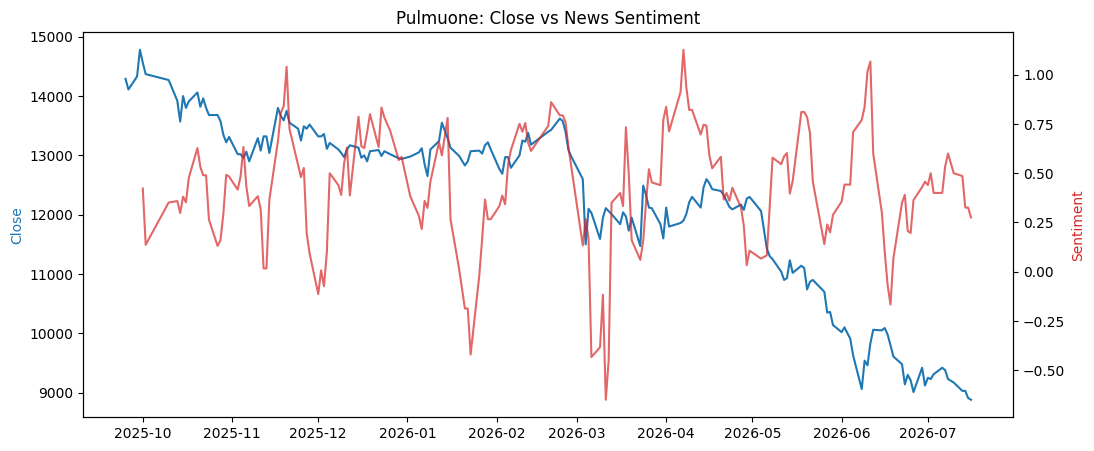

In [ ]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12,5))

ax1.plot(merged['day'], merged['Close'], color='tab:blue', label='Close')
ax1.set_ylabel('Close', color='tab:blue')

ax2 = ax1.twinx()   # 오른쪽에 두 번째 y축
ax2.plot(merged['day'], merged['avg_senti'].rolling(5).mean(),
         color='tab:red', alpha=0.7, label='Sentiment(5d avg)')
ax2.set_ylabel('Sentiment', color='tab:red')

plt.title('Pulmuone: Close vs News Sentiment')
plt.show()


In [ ]:
# 감성 점수와 다음 날 수익률의 상관관계
merged['return_next'] = merged['Close'].pct_change().shift(-1)
corr = merged['avg_senti'].corr(merged['return_next'])
print('상관계수:', round(corr, 4))


상관계수: 0.2149


In [ ]:
from scipy import stats

valid = merged.dropna(subset=['avg_senti', 'return_next'])
r, p = stats.pearsonr(valid['avg_senti'], valid['return_next'])
print('상관계수:', round(r, 4), '/ p-value:', round(p, 4))


상관계수: 0.2149 / p-value: 0.0029


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 특징: 오늘 감성, 오늘 수익률 / 정답: 내일 상승(1)/하락(0)
data = merged.dropna(subset=['avg_senti', 'return_next']).copy()
data['return_today'] = data['Close'].pct_change()
data = data.dropna()

X = data[['avg_senti', 'return_today']]
y = (data['return_next'] > 0).astype(int)

# 시계열이라 섞지 않고 앞 80% 학습 / 뒤 20% 평가
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False)

model = LogisticRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print('정확도:', round(accuracy_score(y_test, pred), 4))
print('F1:', round(f1_score(y_test, pred), 4))
print(confusion_matrix(y_test, pred))


정확도: 0.6579
F1: 0.1333
[[24  1]
 [12  1]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# 1) 로지스틱 + 클래스 불균형 보정
model2 = LogisticRegression(class_weight='balanced')
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)
print('로지스틱(balanced) 정확도:', round(accuracy_score(y_test, pred2), 4),
      '/ F1:', round(f1_score(y_test, pred2), 4))
print(confusion_matrix(y_test, pred2))

# 2) Random Forest 비교
model3 = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                random_state=42)
model3.fit(X_train, y_train)
pred3 = model3.predict(X_test)
print('RF 정확도:', round(accuracy_score(y_test, pred3), 4),
      '/ F1:', round(f1_score(y_test, pred3), 4))
print(confusion_matrix(y_test, pred3))


로지스틱(balanced) 정확도: 0.6053 / F1: 0.5161
[[15 10]
 [ 5  8]]
RF 정확도: 0.6053 / F1: 0.4
[[18  7]
 [ 8  5]]
